[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

# Predicting Premium Wine from Physicochemical Measurements

**CHE1147 Chemical Data Science and Engineering, Fall 2026. Team 8 final project.**

## Machine learning for screening premium wines

Wine quality is certified by trained sensory panels. Panels are slow and expensive, and different tasters can score the same wine differently. Physicochemical tests (acidity, sugar, sulphur dioxide, alcohol, ...) are cheap and run routinely. If these routine tests can flag the wines that a panel is most likely to rate highly, the panel's time can be spent where it matters most.

In this notebook we build classification models that predict whether a wine is **premium** (sensory quality score of 7 or more) from eleven lab measurements. We use the UCI Wine Quality dataset of red and white Vinho Verde wines ([Cortez et al., 2009](https://doi.org/10.1016/j.dss.2009.05.016)).

**Research question.** Can supervised models using eleven routine physicochemical measurements identify premium wines, separately for red and white wine? We aim for a test PR-AUC of at least 0.60, above the no-skill level and above a logistic regression baseline. We also ask which measurements drive the predictions, and whether a model trained on one wine type works on the other.

The workflow follows the course tutorials:

| Section | Step | Course reference |
|---|---|---|
| 0 | Setup, data loading, cleaning | Tutorials 3 and 4 |
| 1 | Target definition and stratified train/test split | Tutorials 4 and 5 |
| 2 | Exploratory data analysis on the training set | Tutorials 3 and 4 |
| 3 | Preprocessing and feature checks | Tutorials 4 and 5 |
| 4 | Classification metrics and baselines | Tutorial 5 |
| 5 | Models: logistic regression, k-NN, random forest, XGBoost | Tutorials 4 and 5 |
| 6 | Hyperparameter optimization | Tutorials 4 and 9 |
| 7 | Final evaluation on the test set | Tutorial 5 |
| 8 | Interpretation: feature importance and transfer between wine types | Tutorial 4 |
| 9 | Summary | |

Every table is saved to `results/tables` and every figure to `results/figures`. A full run (Runtime > Run all) takes about 10 minutes on Colab, mostly in Section 6.

## 0. Setup programming environment

### 0.1 Installing packages

If you are running this notebook locally after cloning our repository, install the environment from the project root:

```bash
pip install .
```

On Google Colab, the cell below installs the two packages that Colab does not ship with.

In [54]:
# %pip install -q optuna ucimlrepo

### 0.2 Import packages we will need

In [55]:
# basics
import os
import time
import numpy as np

# pandas is used to read/process data
import pandas as pd

# machine learning dependencies
# scaling of data
from sklearn.preprocessing import StandardScaler
# train/test split and cross-validation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
# pipeline to streamline modeling pipelines
from sklearn.pipeline import Pipeline
from sklearn.base import clone
# Dummy model as baseline
from sklearn.dummy import DummyClassifier
# the models we compare
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
# Variance Threshold for feature checks
from sklearn.feature_selection import VarianceThreshold
# metrics to measure model performance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)
# curves and confusion matrix
from sklearn.metrics import roc_curve, auc, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
# permutation importance
from sklearn.inspection import permutation_importance

# hyperparameter optimization (Bayesian optimization with a TPE surrogate)
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# plotting
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

### 0.3 Fix the random seed

Every random step (train/test split, cross-validation folds, model seeds, the Optuna sampler and the bootstrap) uses this seed, so that every run gives the same numbers.

In [56]:
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

### 0.4 Import the data

The dataset has two files, one for red and one for white wine, with eleven measurements and the median quality score of at least three tasters for each wine. We first look for the csv files in the repository's `data/` folder. If they are not there (for example on Colab) we download the dataset from the UCI Machine Learning Repository with `ucimlrepo`.

In [57]:
# load data locally
running_in_colab = 'google.colab' in str(get_ipython())

if running_in_colab:
    PROJECT_DIR = "/content"
else:
    PROJECT_DIR = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
DATA_DIR = os.path.join(PROJECT_DIR, "data")

try:
    parts = []
    for wine_type in ["red", "white"]:
        DATA_FILE = os.path.join(DATA_DIR, f"winequality-{wine_type}.csv")
        part = pd.read_csv(DATA_FILE, sep=";")
        part.columns = [c.replace(" ", "_") for c in part.columns]   # "fixed acidity" -> "fixed_acidity"
        part["type"] = wine_type
        parts.append(part)
    df = pd.concat(parts, ignore_index=True)
    print(f"✅ Loaded data from {DATA_DIR}, shape = {df.shape}")

except FileNotFoundError:
    # Fallback: download from the UCI repository (dataset id 186)
    try:
        from ucimlrepo import fetch_ucirepo
        wine_quality = fetch_ucirepo(id=186)
        df = pd.concat([wine_quality.data.features, wine_quality.data.targets], axis=1)
        df["type"] = wine_quality.data.original["color"]
        print(f"🌐 Loaded data from the UCI repository, shape = {df.shape}")
    except Exception as e:
        print(f"❌ Could not find the data in {DATA_DIR} or on the UCI repository.")
        raise e

# shorter names for the two sulphur dioxide columns
df = df.rename(columns={"free_sulfur_dioxide": "free_so2", "total_sulfur_dioxide": "total_so2"})

# folders for the saved tables and figures
TABLE_DIR = os.path.join(PROJECT_DIR, "outputs", "wine-quality-prediction-experiments", "tables")
FIGURE_DIR = os.path.join(PROJECT_DIR, "outputs", "wine-quality-prediction-experiments", "figures")
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

✅ Loaded data from ..\data, shape = (6497, 13)


Let's take a look at the first few rows to see if everything seems reasonable ...

In [58]:
df.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_so2,total_so2,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   fixed_acidity     6497 non-null   float64
 1   volatile_acidity  6497 non-null   float64
 2   citric_acid       6497 non-null   float64
 3   residual_sugar    6497 non-null   float64
 4   chlorides         6497 non-null   float64
 5   free_so2          6497 non-null   float64
 6   total_so2         6497 non-null   float64
 7   density           6497 non-null   float64
 8   pH                6497 non-null   float64
 9   sulphates         6497 non-null   float64
 10  alcohol           6497 non-null   float64
 11  quality           6497 non-null   int64  
 12  type              6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


### 0.5 Understanding the data

Below we define global variables (hence upper case) for the names of our feature and target columns, and the units we will use on figure axes.

In [60]:
# the eleven physicochemical measurements, with units for plotting
FEATURE_LABELS = {
    "fixed_acidity": "Fixed acidity (g/L)",
    "volatile_acidity": "Volatile acidity (g/L)",
    "citric_acid": "Citric acid (g/L)",
    "residual_sugar": "Residual sugar (g/L)",
    "chlorides": "Chlorides (g/L)",
    "free_so2": "Free SO2 (mg/L)",
    "total_so2": "Total SO2 (mg/L)",
    "density": "Density (g/mL)",
    "pH": "pH",
    "sulphates": "Sulphates (g/L)",
    "alcohol": "Alcohol (% vol)",
}
FEATURES = list(FEATURE_LABELS)

TARGET = "premium"          # binary target, defined in section 1.1
PREMIUM_CUTOFF = 7          # a wine is premium if its quality score is 7 or more

### 0.6 Basic data cleaning and preparation

We check for missing values and remove exact duplicate rows. A duplicated wine could end up in both the training and the test set, so the model would be tested on a wine it has already seen (data leakage). The wine type is part of the row, so a red and a white wine with identical measurements are kept as two different wines.

In [61]:
num_rows_with_nan = df.isna().any(axis=1).sum()
print(f"Number of rows with NaN values: {num_rows_with_nan}")

n_raw = df.groupby("type").size()
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_before - len(df)} duplicated rows")

Number of rows with NaN values: 0
Removed 1177 duplicated rows


## 1. Define the target and split the data

### 1.1 Binary target: premium or standard

We binarize the quality score: a wine with a score of 7 or more is **premium** (1), all others are **standard** (0). We build three modelling datasets: red only, white only, and both combined. The combined dataset gets an extra input, `colour` (0 = red, 1 = white), so the model can tell the two types apart.

In [62]:
df[TARGET] = (df["quality"] >= PREMIUM_CUTOFF).astype(int)
df["colour"] = (df["type"] == "white").astype(int)

df_red = df[df["type"] == "red"].reset_index(drop=True)
df_white = df[df["type"] == "white"].reset_index(drop=True)

datasets = {
    "red": (df_red, FEATURES),
    "white": (df_white, FEATURES),
    "combined": (df, FEATURES + ["colour"]),
}
DATASETS = list(datasets)

overview = pd.DataFrame({
    "wines (raw)": [n_raw["red"], n_raw["white"], n_raw.sum()],
    "wines (duplicates removed)": [len(df_red), len(df_white), len(df)],
    "premium wines": [df_red[TARGET].sum(), df_white[TARGET].sum(), df[TARGET].sum()],
    "premium share (%)": [100 * df_red[TARGET].mean(), 100 * df_white[TARGET].mean(), 100 * df[TARGET].mean()],
}, index=DATASETS).round(1)
overview.to_csv(os.path.join(TABLE_DIR, "dataset_overview.csv"))
overview

,wines (raw),wines (duplicates removed),premium wines,premium share (%)
red,1599,1359,184,13.5
white,4898,3961,825,20.8
combined,6497,5320,1009,19.0


Note, we have a class imbalance here: only about 14% of red wines and 21% of white wines are premium. A model that always predicts "standard" would already be 80 to 86% accurate, so accuracy alone would be misleading. We come back to this when choosing our metrics in section 4.

### 1.2 Train/test split with stratification

As in Tutorial 4, we split **before** analysing or transforming the data, so that no information from the test set leaks into our modelling decisions. We use an 80/20 split. Because of the class imbalance we stratify on the target, so the share of premium wines is the same in the training and the test set.

In [63]:
splits = {}
rows = []
for name, (data, features) in datasets.items():
    X = data[features]
    y = data[TARGET]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        train_size=0.8,
        test_size=0.2,
        random_state=RANDOM_SEED,
        stratify=y,
    )
    splits[name] = {"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test}
    rows.append({"dataset": name,
                 "train wines": len(y_train), "train premium": int(y_train.sum()),
                 "test wines": len(y_test), "test premium": int(y_test.sum()),
                 "premium share, train": round(y_train.mean(), 3),
                 "premium share, test": round(y_test.mean(), 3)})

split_table = pd.DataFrame(rows).set_index("dataset")
split_table.to_csv(os.path.join(TABLE_DIR, "train_test_split.csv"))
split_table

,train wines,train premium,test wines,test premium,"premium share, train","premium share, test"
dataset,,,,,,
red,1087,147,272,37,0.135,0.136
white,3168,660,793,165,0.208,0.208
combined,4256,807,1064,202,0.190,0.190


Check that the class distribution is the same in the training and the test set:

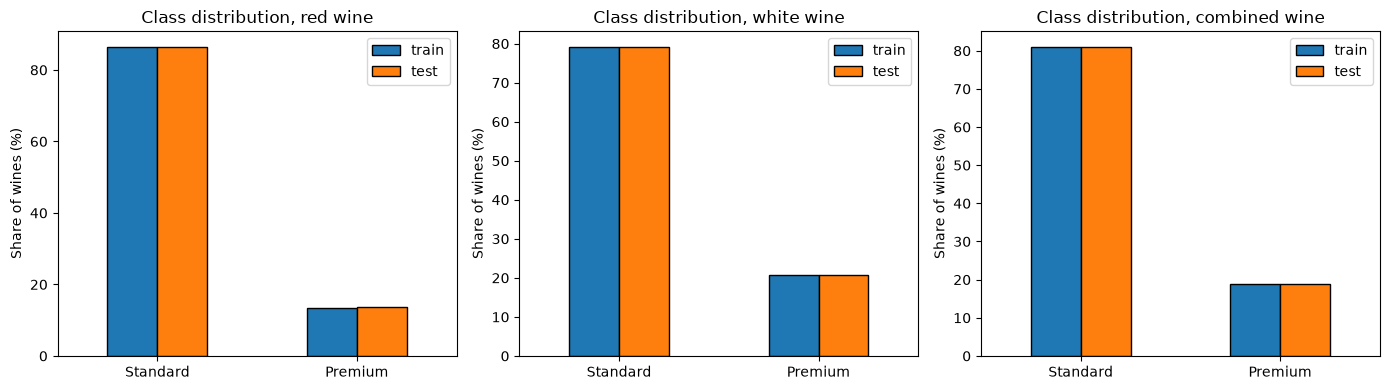

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, DATASETS):
    counts = pd.DataFrame({
        "train": splits[name]["y_train"].value_counts(normalize=True).sort_index() * 100,
        "test": splits[name]["y_test"].value_counts(normalize=True).sort_index() * 100,
    })
    counts.index = ["Standard", "Premium"]
    counts.plot.bar(ax=ax, rot=0, color=["tab:blue", "tab:orange"], edgecolor="black")
    ax.set_title(f"Class distribution, {name} wine")
    ax.set_ylabel("Share of wines (%)")
plt.tight_layout()
plt.show()

## 2. Exploratory data analysis (EDA)

After we have put the test set aside, we can give the training set a closer look. We want to answer four questions that shape the rest of the pipeline:

- How is the quality score distributed, and where does the premium cut-off fall?
- How are the measurements distributed? Are some of them skewed?
- Which measurements are correlated with quality, and with each other?
- Are there extreme values, and should they be removed?

In [65]:
# training rows of the red and white datasets, with the quality score added back for EDA
train_red = df_red.loc[splits["red"]["X_train"].index]
train_white = df_white.loc[splits["white"]["X_train"].index]
WINE_COLOURS = {"red": "#8B1E3F", "white": "#C9A227", "combined": "grey"}

def save_figure(fig, name):
    """Save a figure at 300 dpi in results/figures."""
    fig.savefig(os.path.join(FIGURE_DIR, f"{name}.png"), dpi=300, bbox_inches="tight")

### 2.1 Summary statistics

`describe()` gives the mean, spread and range of each measurement. We add the skewness: 0 means a symmetric distribution, values above about 1 mean a long right tail.

In [66]:
def summary_statistics(data):
    stats = data[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]]
    stats["skew"] = data[FEATURES].skew()
    return stats.rename(columns={"50%": "median"})

summary_stats = pd.concat({"Red": summary_statistics(train_red), "White": summary_statistics(train_white)}, axis=1).round(3)
summary_stats.to_csv(os.path.join(TABLE_DIR, "summary_statistics.csv"))
summary_stats

Red                                           White  \
                    mean     std    min  median      max   skew     mean   
fixed_acidity      8.325   1.760  4.600   7.900   15.900  0.982    6.837   
volatile_acidity   0.529   0.185  0.120   0.520    1.580  0.785    0.282   
citric_acid        0.275   0.193  0.000   0.260    0.790  0.263    0.335   
residual_sugar     2.548   1.394  0.900   2.200   15.500  4.622    5.965   
chlorides          0.088   0.047  0.012   0.079    0.611  5.463    0.046   
free_so2          16.180  10.651  1.000  14.000   72.000  1.285   34.946   
total_so2         47.928  34.091  6.000  39.000  289.000  1.567  137.409   
density            0.997   0.002  0.990   0.997    1.004  0.079    0.994   
pH                 3.309   0.155  2.860   3.310    4.010  0.272    3.193   
sulphates          0.658   0.171  0.330   0.620    1.980  2.364    0.491   
alcohol           10.424   1.083  8.400  10.100   14.900  0.837   10.591   

                                                          
                     std    min   median      max   skew  
fixed_acidity      0.859  3.800    6.800   14.200  0.711  
volatile_acidity   0.105  0.080    0.260    1.100  1.690  
citric_acid        0.125  0.000    0.320    1.660  1.344  
residual_sugar     4.905  0.700    4.700   65.800  1.427  
chlorides          0.024  0.009    0.042    0.346  4.742  
free_so2          17.597  2.000   33.000  289.000  1.740  
total_so2         43.453  9.000  133.000  440.000  0.449  
density            0.003  0.987    0.993    1.039  1.479  
pH                 0.151  2.720    3.180    3.800  0.425  
sulphates          0.115  0.220    0.480    1.060  0.949  
alcohol            1.223  8.000   10.400   14.200  0.445

### 2.2 Distribution of the quality score

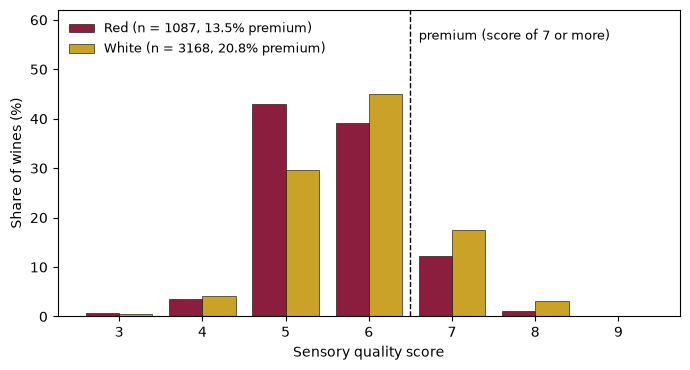

In [67]:
fig, ax = plt.subplots(figsize=(7, 3.8))
scores = np.arange(3, 10)
for k, (name, data) in enumerate([("red", train_red), ("white", train_white)]):
    share = data["quality"].value_counts(normalize=True).reindex(scores, fill_value=0) * 100
    ax.bar(scores + (k - 0.5) * 0.4, share, width=0.4, color=WINE_COLOURS[name], edgecolor="black", linewidth=0.4,
           label=f"{name.capitalize()} (n = {len(data)}, {100 * data[TARGET].mean():.1f}% premium)")
ax.set_ylim(0, 62)
ax.axvline(PREMIUM_CUTOFF - 0.5, color="k", linestyle="--", linewidth=1)
ax.text(PREMIUM_CUTOFF - 0.4, 56, "premium (score of 7 or more)", fontsize=9)
ax.set_xlabel("Sensory quality score")
ax.set_ylabel("Share of wines (%)")
ax.set_xticks(scores)
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout()
save_figure(fig, "eda_quality_distribution")
plt.show()

Most wines score 5 or 6; very few score 3 or 9. The cut-off at 7 keeps the clearly better wines as a minority class, which is what a screening tool needs to find.

### 2.3 Distribution of the measurements

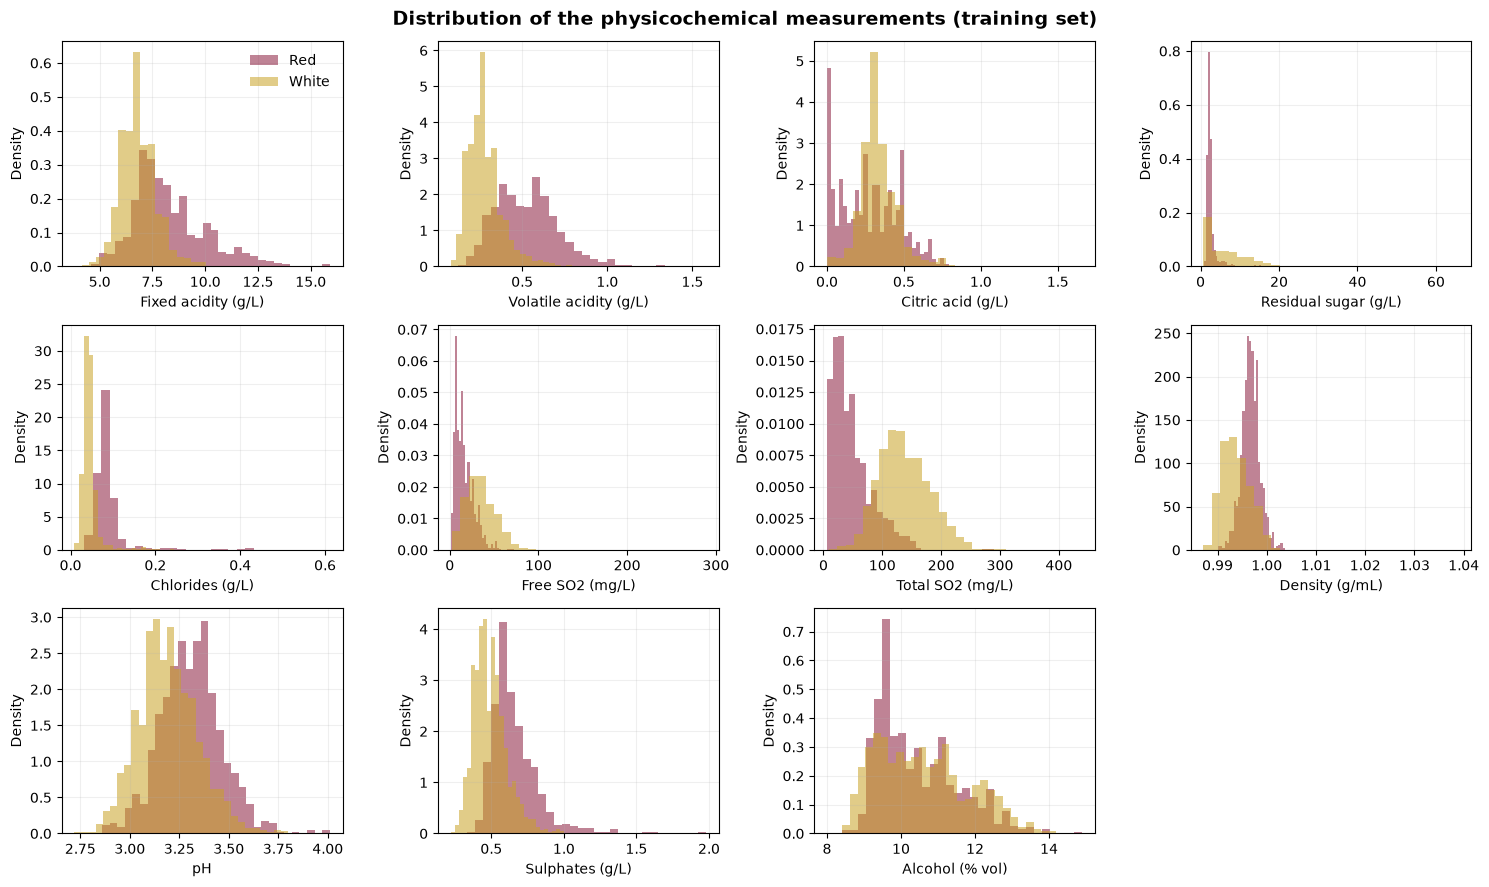

In [68]:
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
fig.suptitle("Distribution of the physicochemical measurements (training set)", fontsize=14, fontweight="bold")

for i, feature in enumerate(FEATURES):
    row = i // 4
    col = i % 4
    for name, data in [("red", train_red), ("white", train_white)]:
        axes[row, col].hist(data[feature], bins=30, alpha=0.55, density=True,
                            color=WINE_COLOURS[name], label=name.capitalize())
    axes[row, col].set_xlabel(FEATURE_LABELS[feature])
    axes[row, col].set_ylabel("Density")
    axes[row, col].grid(True, alpha=0.2)

axes[0, 0].legend(frameon=False)
axes[2, 3].axis("off")   # 11 measurements, so the last panel stays empty
plt.tight_layout()
save_figure(fig, "eda_feature_distributions")
plt.show()

Red and white wines have clearly different chemistry (for example, white wines have much more total SO2 and residual sugar), which is why we model them separately as well as together. Several measurements, such as residual sugar, chlorides and sulphates, have long right tails; we deal with this in section 3.1.

### 2.4 Correlations

As in Tutorial 3, we use `DataFrame.corr()` to calculate the pairwise Pearson correlation between the measurements and with the quality score.

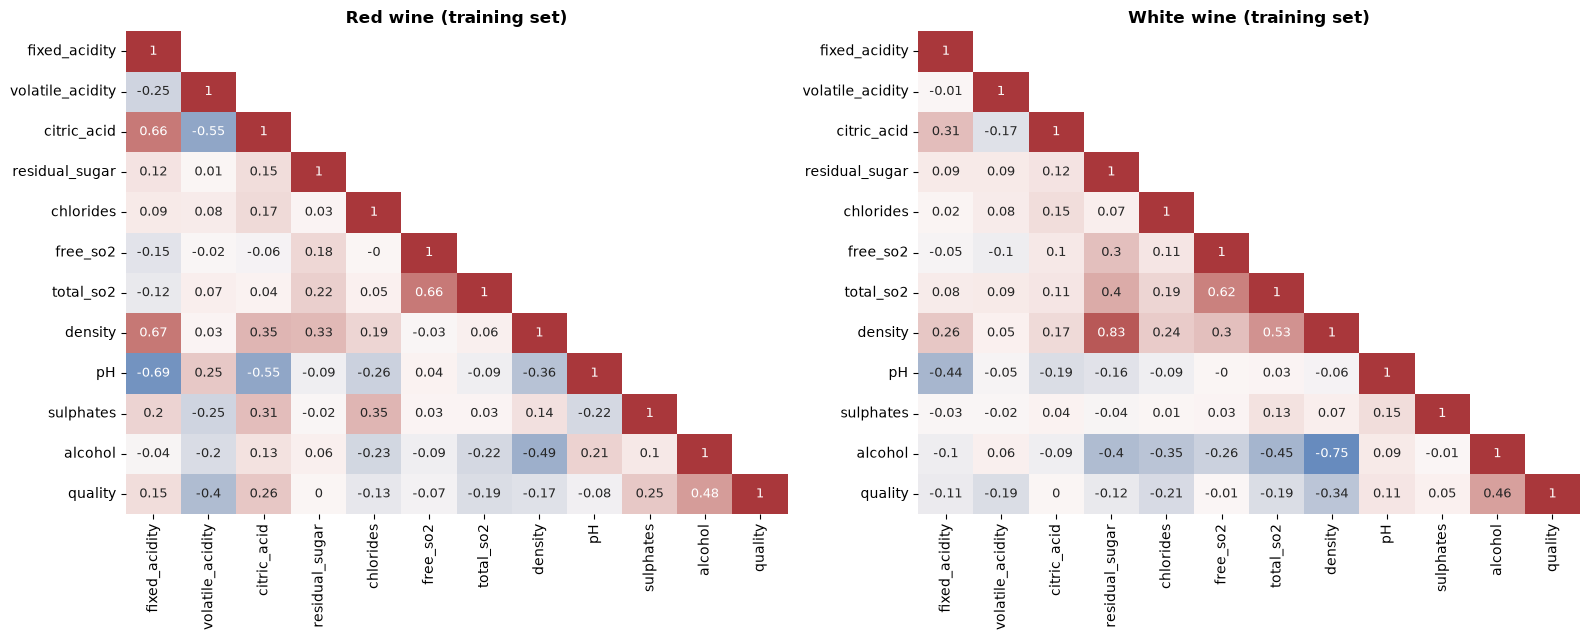

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (name, data) in zip(axes, [("red", train_red), ("white", train_white)]):
    correlation_matrix = data[FEATURES + ["quality"]].corr().round(2)
    mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), 1)   # mask the upper triangle
    sns.heatmap(correlation_matrix, mask=mask, annot=True, annot_kws={"size": 9},
                cmap="vlag", vmin=-1, vmax=1, center=0, cbar=False, ax=ax)
    ax.set_title(f"{name.capitalize()} wine (training set)", fontweight="bold")
plt.tight_layout()
save_figure(fig, "eda_correlation_heatmaps")
plt.show()

In [70]:
# correlation of each measurement with the quality score, strongest first
quality_correlation = pd.DataFrame({
    "red": train_red[FEATURES].corrwith(train_red["quality"]),
    "white": train_white[FEATURES].corrwith(train_white["quality"]),
}).round(2)
quality_correlation.loc[quality_correlation.abs().max(axis=1).sort_values(ascending=False).index]

,red,white
alcohol,0.48,0.46
volatile_acidity,-0.40,-0.19
density,-0.17,-0.34
citric_acid,0.26,0.00
sulphates,0.25,0.05
chlorides,-0.13,-0.21
total_so2,-0.19,-0.19
fixed_acidity,0.15,-0.11
residual_sugar,0.00,-0.12
pH,-0.08,0.11


Alcohol has the strongest correlation with quality for both wine types. Volatile acidity (a sign of acetic spoilage) is the next strongest for red wine and density for white wine. Each single correlation is moderate at best, so we expect to need several measurements together to identify premium wines.

### 2.5 Outliers

A common rule removes any wine with a measurement more than 3 standard deviations from the mean ($|z| > 3$). Before using it, we check which wines it would remove.

In [71]:
def z_score_outliers(data):
    z = (data[FEATURES] - data[FEATURES].mean()) / data[FEATURES].std()
    return (z.abs() > 3).any(axis=1)

red_outliers = z_score_outliers(train_red)
white_outliers = z_score_outliers(train_white)
low_white = train_white["quality"] <= 4

print(f"Wines flagged by |z| > 3: {red_outliers.sum()} red, {white_outliers.sum()} white")
print(f"Share of all white wines flagged:               {100 * white_outliers.mean():.0f}%")
print(f"Share of white wines scoring 4 or less flagged: {100 * white_outliers[low_white].mean():.0f}%")

Wines flagged by |z| > 3: 98 red, 266 white
Share of all white wines flagged:               8%
Share of white wines scoring 4 or less flagged: 25%


The rule would remove low-scoring white wines about three times as often as other wines, and the flagged values are chemically plausible (for example, very sweet wines). Removing them would distort the classes we are trying to model, so **we keep all wines** and reduce the influence of the extreme values with a log transform instead.

## 3. Preprocessing and feature checks

### 3.1 Log transform of the skewed measurements

Five measurements have a long right tail. `np.log1p(x)` $= \log(1 + x)$ pulls the large values in, so the distribution becomes more symmetric.

- **Logistic regression and k-NN** use the size of the numbers, so a few extreme wines would otherwise dominate the weighted sums and the distances.
- **Random forest and XGBoost** are not affected: a tree only asks whether a value is above a cut point, and the log keeps the order of the wines the same.
- **No data leakage:** the transform works on each wine by itself and learns nothing from the other wines, so it gives the same result whether it is applied before or after the split.

In [72]:
SKEWED = ["residual_sugar", "chlorides", "free_so2", "total_so2", "sulphates"]

def log_transform(X):
    """log(1 + x) on the right-skewed measurements. Row by row, nothing is learned from the data."""
    X = X.copy()
    X[SKEWED] = np.log1p(X[SKEWED])
    return X

skew_table = pd.DataFrame({
    "Red, before": train_red[SKEWED].skew(), "Red, after": log_transform(train_red)[SKEWED].skew(),
    "White, before": train_white[SKEWED].skew(), "White, after": log_transform(train_white)[SKEWED].skew(),
}).round(2)
skew_table.to_csv(os.path.join(TABLE_DIR, "skewness_before_after_log.csv"))

# apply the transform to the training and test sets of every dataset
for name in DATASETS:
    splits[name]["X_train"] = log_transform(splits[name]["X_train"])
    splits[name]["X_test"] = log_transform(splits[name]["X_test"])

skew_table

,"Red, before","Red, after","White, before","White, after"
residual_sugar,4.62,2.23,1.43,0.10
chlorides,5.46,4.90,4.74,4.40
free_so2,1.28,-0.07,1.74,-0.79
total_so2,1.57,-0.04,0.45,-0.97
sulphates,2.36,1.64,0.95,0.67


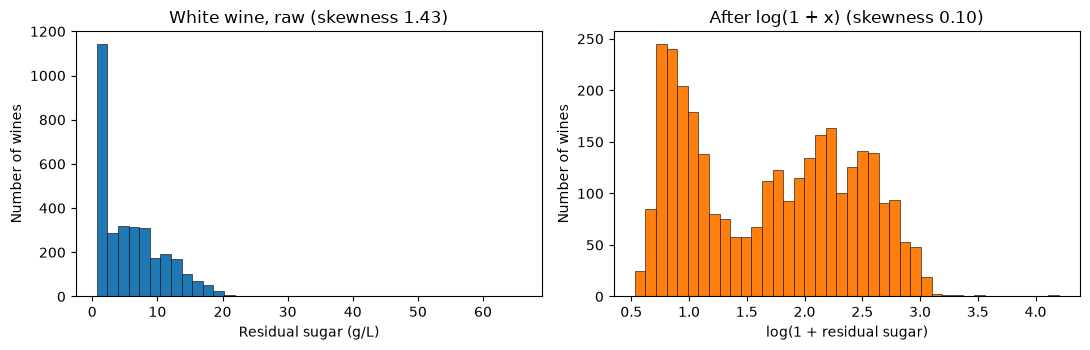

In [73]:
# the effect on one measurement
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
raw_sugar = train_white["residual_sugar"]
axes[0].hist(raw_sugar, bins=40, color="tab:blue", edgecolor="black", linewidth=0.4)
axes[0].set_title(f"White wine, raw (skewness {raw_sugar.skew():.2f})")
axes[0].set_xlabel("Residual sugar (g/L)")
axes[1].hist(np.log1p(raw_sugar), bins=40, color="tab:orange", edgecolor="black", linewidth=0.4)
axes[1].set_title(f"After log(1 + x) (skewness {np.log1p(raw_sugar).skew():.2f})")
axes[1].set_xlabel("log(1 + residual sugar)")
for ax in axes:
    ax.set_ylabel("Number of wines")
plt.tight_layout()
save_figure(fig, "log_transform_residual_sugar")
plt.show()

### 3.2 Remove redundant columns

As in Tutorial 5, we use `VarianceThreshold` to find features with zero variance on the training set, which carry no information.

In [74]:
for name in DATASETS:
    selector = VarianceThreshold(threshold=0)
    selector.fit(splits[name]["X_train"])
    n_removed = (~selector.get_support()).sum()
    print(f"{name:8s}: {n_removed} zero-variance features out of {splits[name]['X_train'].shape[1]}")

red     : 0 zero-variance features out of 11
white   : 0 zero-variance features out of 11
combined: 0 zero-variance features out of 12


### 3.3 Highly correlated features

Two features that are highly correlated with each other carry overlapping information. Following Tutorial 5, we would drop a feature whose absolute Pearson correlation with an earlier feature exceeds 0.90.

In [75]:
CORRELATION_THRESHOLD = 0.90

for name in DATASETS:
    feature_correlation = splits[name]["X_train"].corr(method="pearson").abs()
    upper_triangle = feature_correlation.where(np.triu(np.ones(feature_correlation.shape), k=1).astype(bool))
    correlated_pairs = upper_triangle.stack().sort_values(ascending=False)
    to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > CORRELATION_THRESHOLD)]
    top_pair = correlated_pairs.index[0]
    print(f"{name:8s}: strongest pair {top_pair[0]} / {top_pair[1]} (|r| = {correlated_pairs.iloc[0]:.2f}), "
          f"features to drop: {to_drop}")

red     : strongest pair free_so2 / total_so2 (|r| = 0.78), features to drop: []
white   : strongest pair residual_sugar / density (|r| = 0.75), features to drop: []
combined: strongest pair free_so2 / total_so2 (|r| = 0.78), features to drop: []


No feature passes either check, so all eleven measurements are kept. With only eleven inputs (compared with the 138 MOF descriptors in Tutorial 4), dimensionality is not a problem for the tree models. k-NN is the exception: it is sensitive to uninformative inputs, so in section 5.3 we choose its features with forward selection.

## 4. Classification metrics and baselines

### 4.1 Classification metrics

As in Tutorial 5, we use the metrics computed from the confusion matrix:

$$
\mathrm{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} \qquad
\mathrm{Precision} = \frac{TP}{TP + FP} \qquad
\mathrm{Recall} = \frac{TP}{TP + FN} \qquad
\mathrm{F1} = 2 \times \frac{\mathrm{Precision} \times \mathrm{Recall}}{\mathrm{Precision} + \mathrm{Recall}}
$$

These depend on the **decision threshold** that turns a predicted probability into a yes/no call. We also report two metrics computed from the predicted probabilities over all thresholds:

- **ROC-AUC**, the area under the ROC curve (true positive rate against false positive rate), as in Tutorial 5. No skill gives 0.5.
- **PR-AUC** (average precision), the area under the precision-recall curve. No skill gives the share of premium wines, so about 0.14 for red and 0.21 for white.

**PR-AUC is our main metric.** With an imbalanced target, ROC-AUC can look good even when most wines flagged as premium are not, because the many standard wines keep the false positive rate low. PR-AUC focuses on the premium class, which is the class we want to find.

In [76]:
def get_classification_metrics(model, X, y_true, threshold=0.5):
    """
    Get a dictionary with classification metrics:

    model: fitted sklearn-like model with a predict_proba method
    X: feature matrix
    y_true: ground truth binary labels (1 = premium, 0 = standard)
    threshold: predicted probability above which a wine is called premium
    """
    y_proba = model.predict_proba(X)[:, 1]          # probability of premium
    y_pred = (y_proba >= threshold).astype(int)    # yes/no call at the threshold

    metrics_dict = {
        "pr_auc": average_precision_score(y_true, y_proba),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }
    return metrics_dict

### 4.2 Cross-validation on the training set

To compare models we must not use the test set, otherwise we would be choosing the model based on the test results. Instead, we use **5-fold stratified cross-validation** on the training set: the training set is split into 5 folds, each model is trained on 4 folds and evaluated on the fifth, and this is repeated 5 times. We use **the same folds for every model**, so the comparison is fair.

In [77]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

def get_cv_metrics(model, X, y):
    """5-fold stratified cross-validation. Returns one row of metrics per fold."""
    rows = []
    for fold, (train_idx, val_idx) in enumerate(CV.split(X, y)):
        fold_model = clone(model)   # a fresh, unfitted copy for every fold
        fold_model.fit(X.iloc[train_idx], y.iloc[train_idx])
        metrics = get_classification_metrics(fold_model, X.iloc[val_idx], y.iloc[val_idx])
        rows.append({"fold": fold + 1, **metrics})
    return pd.DataFrame(rows)

### 4.3 Dummy baseline

As in Tutorials 4 and 5, a `DummyClassifier` that always predicts the most frequent class gives the no-skill level. Any useful model must beat it.

In [78]:
def make_dummy():
    return DummyClassifier(strategy="most_frequent")

cv_results = {name: {} for name in DATASETS}   # cross-validation results of every model before tuning
for name in DATASETS:
    cv_results[name]["Dummy"] = get_cv_metrics(make_dummy(), splits[name]["X_train"], splits[name]["y_train"])
    print(f"{name:8s} dummy: CV accuracy {cv_results[name]['Dummy']['accuracy'].mean():.3f}, "
          f"CV PR-AUC {cv_results[name]['Dummy']['pr_auc'].mean():.3f}, "
          f"CV recall {cv_results[name]['Dummy']['recall'].mean():.3f}")

red      dummy: CV accuracy 0.865, CV PR-AUC 0.135, CV recall 0.000
white    dummy: CV accuracy 0.792, CV PR-AUC 0.208, CV recall 0.000
combined dummy: CV accuracy 0.810, CV PR-AUC 0.190, CV recall 0.000


The dummy is 79 to 86% accurate while finding no premium wine at all (recall 0). This confirms that accuracy is not a useful metric for this problem.

## 5. Models

We compare four models of increasing flexibility. Each starts from simple, hand-picked settings here, and is tuned in section 6.

| Model | How it decides | Why we include it |
|---|---|---|
| Logistic regression | Weighted sum of the measurements, turned into a probability by the sigmoid | Linear baseline from Tutorial 5 |
| k-NN | Vote of the most similar training wines | Instance-based model from Tutorial 4 |
| Random forest | Average of many trees, each grown on a bootstrap sample with random feature subsets | Tree ensemble (bagging) from Tutorial 4 |
| XGBoost | Small trees added one after another, each correcting the errors of the previous ones | Tree ensemble (boosting) from Tutorial 5 |

Logistic regression and k-NN are built as **pipelines** with `StandardScaler`, as in Tutorial 4 section 7.1. Inside cross-validation the scaler is refitted on the training folds only, so the validation wines never influence the scaling. The tree models do not need scaling.

### 5.1 Logistic regression

In [79]:
def make_lr_pipeline(params={"C": 1.0, "max_iter": 5000}):
    """Scaling + logistic regression with an L2 penalty (C is the inverse of the penalty strength)."""
    return Pipeline([
        ("scaling", StandardScaler()),
        ("lr", LogisticRegression(**params)),
    ])

for name in DATASETS:
    cv_results[name]["Logistic regression"] = get_cv_metrics(
        make_lr_pipeline(), splits[name]["X_train"], splits[name]["y_train"])
    print(f"{name:8s} logistic regression: CV PR-AUC {cv_results[name]['Logistic regression']['pr_auc'].mean():.3f}")

red      logistic regression: CV PR-AUC 0.508
white    logistic regression: CV PR-AUC 0.543
combined logistic regression: CV PR-AUC 0.543


### 5.2 k-NN with forward feature selection

k-NN measures similarity as a distance over all inputs, so inputs that carry no useful information add noise to the distance (Tutorial 4, section 11). We therefore select its features with **forward selection**, a wrapper method:

1. Start with no features.
2. Try adding each remaining feature, and score each candidate subset with cross-validation.
3. Keep the addition with the best mean CV PR-AUC.
4. Repeat until every feature has been added, then choose the subset size with the best score over the complete path.

This is the same procedure as `forward_selection_path` in Tutorial 4, with PR-AUC instead of MAE (so higher is better).

In [80]:
def make_knn_pipeline(params={"n_neighbors": 5, "weights": "uniform", "metric": "euclidean"}):
    """Scaling + k-NN classifier. Each call returns a new, unfitted pipeline."""
    return Pipeline([
        ("scaling", StandardScaler()),
        ("knn", KNeighborsClassifier(**params)),
    ])

def forward_selection_path(X, y, estimator):
    """Return the feature order and mean CV PR-AUC for every subset size (training data only)."""
    selected = []
    remaining = list(X.columns)
    history = []

    while remaining:
        best_score = -np.inf

        # compare every possible next addition to the current subset
        for feature in remaining:
            candidate_features = selected + [feature]
            scores = cross_val_score(estimator, X[candidate_features], y, cv=CV, scoring="average_precision")
            if scores.mean() > best_score:
                best_score = float(scores.mean())
                best_feature = feature

        # always add the best candidate, even if the score went down
        selected.append(best_feature)
        remaining.remove(best_feature)
        history.append({"n_features": len(selected), "added_feature": best_feature, "cv_pr_auc": best_score})

    return selected, pd.DataFrame(history)

In [81]:
knn_features = {}
forward_history = {}
for name in DATASETS:
    feature_order, forward_history[name] = forward_selection_path(
        splits[name]["X_train"], splits[name]["y_train"], make_knn_pipeline())
    best_row = forward_history[name].loc[forward_history[name]["cv_pr_auc"].idxmax()]
    knn_features[name] = feature_order[:int(best_row["n_features"])]
    cv_results[name]["KNN"] = get_cv_metrics(
        make_knn_pipeline(), splits[name]["X_train"][knn_features[name]], splits[name]["y_train"])
    print(f"{name:8s} k-NN keeps {len(knn_features[name])} features: {knn_features[name]}")

pd.Series({name: ", ".join(f) for name, f in knn_features.items()}, name="knn_features").to_csv(
    os.path.join(TABLE_DIR, "knn_selected_features.csv"))

red      k-NN keeps 7 features: ['alcohol', 'citric_acid', 'sulphates', 'pH', 'density', 'chlorides', 'fixed_acidity']
white    k-NN keeps 10 features: ['alcohol', 'total_so2', 'pH', 'sulphates', 'free_so2', 'citric_acid', 'density', 'residual_sugar', 'chlorides', 'volatile_acidity']
combined k-NN keeps 9 features: ['alcohol', 'free_so2', 'residual_sugar', 'density', 'sulphates', 'total_so2', 'fixed_acidity', 'chlorides', 'pH']


### 5.3 Random forest

As in Tutorial 4 section 12, the forest needs no scaler, so its pipeline has a single step. We start from 300 trees with the scikit-learn default settings.

In [82]:
def make_rf_pipeline(params={"n_estimators": 300, "random_state": RANDOM_SEED, "n_jobs": -1}):
    """Random forest. Trees do not require scaling."""
    return Pipeline([
        ("forest", RandomForestClassifier(**params)),
    ])

for name in DATASETS:
    cv_results[name]["Random forest"] = get_cv_metrics(
        make_rf_pipeline(), splits[name]["X_train"], splits[name]["y_train"])
    print(f"{name:8s} random forest: CV PR-AUC {cv_results[name]['Random forest']['pr_auc'].mean():.3f}")

red      random forest: CV PR-AUC 0.541
white    random forest: CV PR-AUC 0.596
combined random forest: CV PR-AUC 0.569


### 5.4 XGBoost with early stopping

Boosting adds trees one after another, so the number of trees controls how closely the model fits the training data. We use **early stopping**: inside each training fold, trees are added until the validation PR-AUC has not improved for 50 rounds. The median best number of trees across the five folds is reported for reference. These starting settings were picked by hand: a slow learning rate (0.03), deep trees (depth 20) with at least 16 wines' weight per leaf, row and column subsampling, and L1 and L2 penalties.

In [83]:
XGB_PARAMS = {
    "objective": "binary:logistic",
    "learning_rate": 0.03,
    "max_depth": 20,
    "min_child_weight": 16,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 1,
    "reg_lambda": 5,
    "eval_metric": "aucpr",     # early stopping watches the validation PR-AUC
    "random_state": RANDOM_SEED,
    "n_jobs": -1,
}

def xgb_cross_validation(X, y):
    """5-fold CV with early stopping. Returns the median best number of trees, the fold metrics and the learning curves."""
    rows, best_iterations, learning_curves = [], [], []
    for fold, (train_idx, val_idx) in enumerate(CV.split(X, y)):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

        model = XGBClassifier(**XGB_PARAMS, n_estimators=1000, early_stopping_rounds=50)
        model.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_val, y_val)], verbose=False)

        best_iterations.append(model.best_iteration + 1)
        learning_curves.append(model.evals_result())
        rows.append({"fold": fold + 1, **get_classification_metrics(model, X_val, y_val)})
    return int(np.median(best_iterations)), pd.DataFrame(rows), learning_curves

xgb_trees, xgb_curves = {}, {}
for name in DATASETS:
    xgb_trees[name], cv_results[name]["XGBoost"], xgb_curves[name] = xgb_cross_validation(
        splits[name]["X_train"], splits[name]["y_train"])
    print(f"{name:8s} XGBoost: early stopping chose {xgb_trees[name]} trees, "
          f"CV PR-AUC {cv_results[name]['XGBoost']['pr_auc'].mean():.3f}")

red      XGBoost: early stopping chose 98 trees, CV PR-AUC 0.538
white    XGBoost: early stopping chose 177 trees, CV PR-AUC 0.557
combined XGBoost: early stopping chose 170 trees, CV PR-AUC 0.555


Note: the k-NN and XGBoost scores above are slightly optimistic, because the same folds that score the model also chose the features or the number of trees. The untouched test set in section 7 gives the unbiased result.

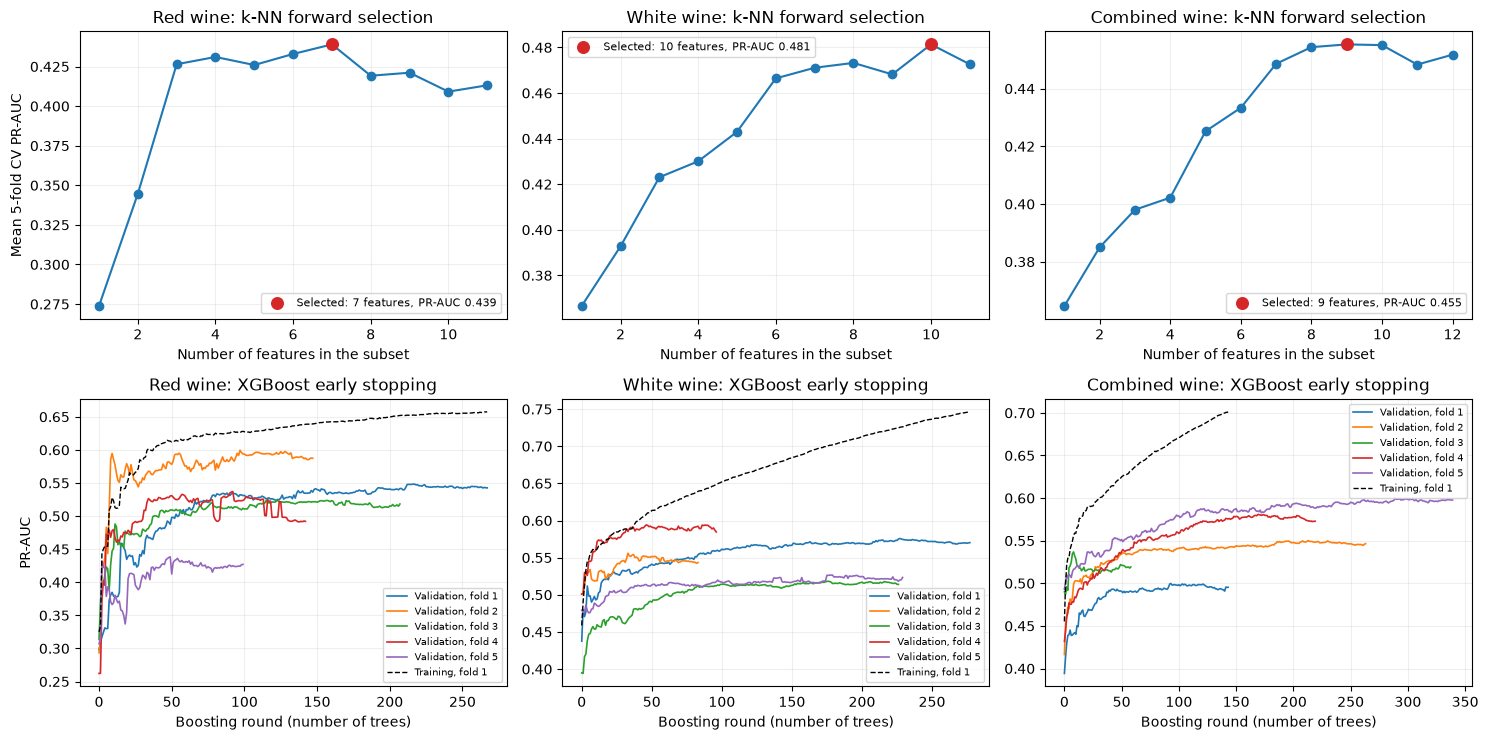

In [84]:
# diagnostics of k-NN forward selection (top) and XGBoost early stopping (bottom)
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for j, name in enumerate(DATASETS):
    history = forward_history[name]
    best_row = history.loc[history["cv_pr_auc"].idxmax()]
    axes[0, j].plot(history["n_features"], history["cv_pr_auc"], marker="o", color="tab:blue")
    axes[0, j].scatter(best_row["n_features"], best_row["cv_pr_auc"], color="tab:red", s=70, zorder=3,
                       label=f"Selected: {int(best_row['n_features'])} features, PR-AUC {best_row['cv_pr_auc']:.3f}")
    axes[0, j].set_title(f"{name.capitalize()} wine: k-NN forward selection")
    axes[0, j].set_xlabel("Number of features in the subset")
    axes[0, j].legend(fontsize=8)

    for fold, curve in enumerate(xgb_curves[name]):
        axes[1, j].plot(curve["validation_1"]["aucpr"], lw=1.2, label=f"Validation, fold {fold + 1}")
    axes[1, j].plot(xgb_curves[name][0]["validation_0"]["aucpr"], "k--", lw=1, label="Training, fold 1")
    axes[1, j].set_title(f"{name.capitalize()} wine: XGBoost early stopping")
    axes[1, j].set_xlabel("Boosting round (number of trees)")
    axes[1, j].legend(fontsize=7)
for ax in axes.flat:
    ax.grid(alpha=0.2)
axes[0, 0].set_ylabel("Mean 5-fold CV PR-AUC")
axes[1, 0].set_ylabel("PR-AUC")
plt.tight_layout()
save_figure(fig, "baseline_diagnostics")
plt.show()

The XGBoost training PR-AUC keeps rising while the validation PR-AUC levels off after a few hundred trees: the model starts to fit the training wines more closely than it generalizes, which is the bias-variance trade-off from the lectures.

### 5.5 Comparison before tuning

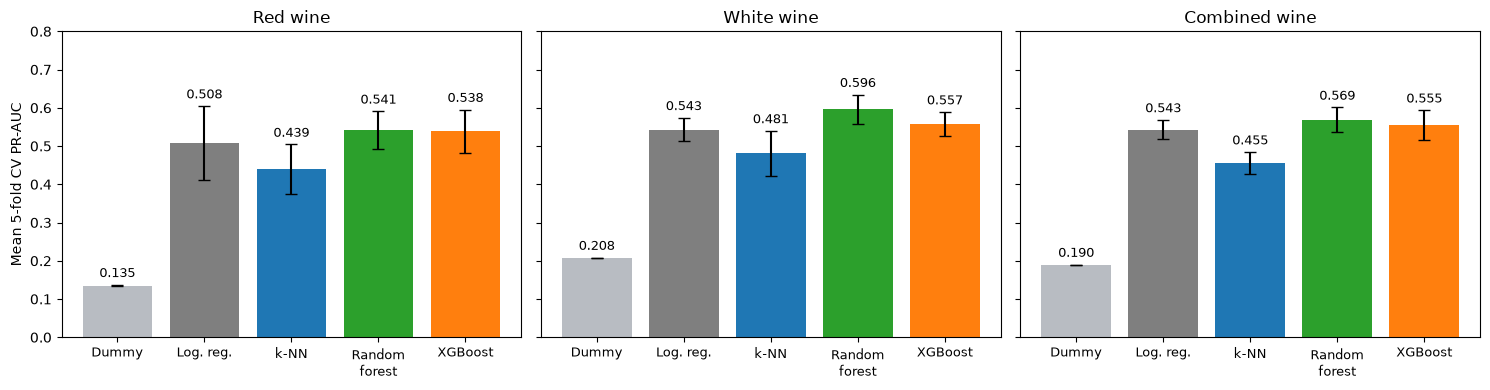

,dataset,model,cv_pr_auc,cv_pr_auc_sd,cv_roc_auc,accuracy,precision,recall,f1
0,red,Dummy,0.135,0.002,0.500,0.865,0.000,0.000,0.000
1,red,Logistic regression,0.508,0.096,0.871,0.873,0.568,0.306,0.395
2,red,KNN,0.439,0.065,0.829,0.877,0.574,0.374,0.448
3,red,Random forest,0.541,0.049,0.872,0.876,0.575,0.299,0.392
4,red,XGBoost,0.538,0.057,0.861,0.879,0.563,0.183,0.271
5,white,Dummy,0.208,0.000,0.500,0.792,0.000,0.000,0.000
6,white,Logistic regression,0.543,0.031,0.820,0.813,0.593,0.330,0.424
7,white,KNN,0.481,0.058,0.781,0.816,0.580,0.433,0.495
8,white,Random forest,0.596,0.039,0.842,0.830,0.671,0.364,0.471
9,white,XGBoost,0.557,0.032,0.826,0.805,0.520,0.206,0.269


In [85]:
MODELS = ["Dummy", "Logistic regression", "KNN", "Random forest", "XGBoost"]
MODEL_COLOURS = {"Dummy": "#B8BCC2", "Logistic regression": "tab:grey", "KNN": "tab:blue",
                 "Random forest": "tab:green", "XGBoost": "tab:orange"}
SHORT_NAMES = {"Dummy": "Dummy", "Logistic regression": "Log. reg.", "KNN": "k-NN",
               "Random forest": "Random\nforest", "XGBoost": "XGBoost"}

rows = []
for name in DATASETS:
    for model_name in MODELS:
        folds = cv_results[name][model_name]
        rows.append({"dataset": name, "model": model_name,
                     "cv_pr_auc": folds["pr_auc"].mean(), "cv_pr_auc_sd": folds["pr_auc"].std(),
                     "cv_roc_auc": folds["roc_auc"].mean(), "accuracy": folds["accuracy"].mean(),
                     "precision": folds["precision"].mean(), "recall": folds["recall"].mean(),
                     "f1": folds["f1"].mean()})
baseline_table = pd.DataFrame(rows)
baseline_table.to_csv(os.path.join(TABLE_DIR, "baseline_cv_results.csv"), index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes, DATASETS):
    t = baseline_table[baseline_table["dataset"] == name]
    bars = ax.bar(range(len(t)), t["cv_pr_auc"], yerr=t["cv_pr_auc_sd"], capsize=4,
                  color=[MODEL_COLOURS[m] for m in t["model"]])
    for i, (value, sd) in enumerate(zip(t["cv_pr_auc"], t["cv_pr_auc_sd"])):
        ax.text(i, value + sd + 0.02, f"{value:.3f}", ha="center", fontsize=9)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([SHORT_NAMES[m] for m in t["model"]], fontsize=9)
    ax.set_title(f"{name.capitalize()} wine")
    ax.set_ylim(0, 0.8)
axes[0].set_ylabel("Mean 5-fold CV PR-AUC")
plt.tight_layout()
save_figure(fig, "baseline_cv_pr_auc")
plt.show()

baseline_table.round(3)

**Observations before tuning.**

- Every model is far above the dummy (PR-AUC 0.14 to 0.21), so the measurements do carry information about quality.
- Random forest has the best cross-validated PR-AUC on all three datasets with its default settings.
- k-NN is the weakest model before tuning. With only 5 neighbours its probability estimates are coarse (only 0, 0.2, 0.4, ... are possible), which hurts a ranking metric such as PR-AUC.
- At the default 0.5 threshold, recall is low for every model (below 45%): the models are reluctant to call a wine premium because premium wines are rare. We address this with the decision threshold in section 7.1.

## 6. Hyperparameter optimization

In Tutorial 4 we tuned ridge regression with `GridSearchCV`, and we saw that grid search is not the most efficient approach: random search, and especially Bayesian optimization, need fewer evaluations to find good settings. Our models have up to eight hyperparameters, so a grid would be far too large (even 5 values each for XGBoost would be $5^8 \approx 390{,}000$ combinations).

We therefore use **Optuna**, whose Tree-structured Parzen Estimator (TPE) is a form of **Bayesian optimization** (Tutorial 9). As in the BO loop of Tutorial 9:

1. A few random trials give an initial set of (settings, score) pairs.
2. A surrogate model of the score is fitted to all trials so far.
3. The next settings are chosen where the surrogate expects improvement, balancing **exploitation** (near the best settings so far) and **exploration** (regions not yet tried).
4. The new settings are evaluated (here: 5-fold CV on the training set) and added to the history, and the loop repeats.

The objective is the **mean 5-fold CV PR-AUC on the training set**, with the same folds as section 5. The test set is not used. For each dataset, the model with the best tuned CV PR-AUC is selected.

| Model | Hyperparameters tuned | Trials |
|---|---|---|
| Logistic regression | penalty strength `C`, class weighting | 30 |
| k-NN | number of neighbours, uniform or distance weighting, Euclidean or Manhattan distance (on the features chosen in 5.2) | 40 |
| Random forest | features tried per split, smallest leaf, maximum depth, class weighting | 25 |
| XGBoost | learning rate, tree depth, minimum child weight, row and column subsampling, L1 and L2 penalties, number of trees | 30 |

In [86]:
# search space of each model: a function that asks the Optuna trial for one set of settings
def lr_space(trial):
    return {"C": trial.suggest_float("C", 1e-3, 100, log=True),                              # inverse of the L2 penalty strength
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),   # give premium wines more weight, or not
            "max_iter": 5000}                                                                # fixed, not tuned

def knn_space(trial):
    return {"n_neighbors": trial.suggest_int("n_neighbors", 3, 101, step=2),                 # odd numbers, so votes cannot tie
            "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),         # equal votes, or closer wines count more
            "metric": trial.suggest_categorical("metric", ["euclidean", "manhattan"])}        # how distance is measured

def rf_space(trial):
    return {"max_features": trial.suggest_int("max_features", 1, 8),                         # measurements tried at each split
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),                # smallest allowed leaf
            "max_depth": trial.suggest_categorical("max_depth", [None, 6, 10, 20]),          # None = grow until the leaves are pure
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced_subsample"]),
            "n_estimators": 300, "random_state": RANDOM_SEED, "n_jobs": -1}                  # fixed, not tuned

def xgb_space(trial):
    return {"learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),      # step size per tree
            "max_depth": trial.suggest_int("max_depth", 2, 8),                               # depth of each tree
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),                # minimum weight of wines in a leaf
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),                         # share of wines used per tree
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),           # share of features used per tree
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),               # L1 penalty
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),             # L2 penalty
            "n_estimators": trial.suggest_int("n_estimators", 100, 600, step=50)}            # number of trees

def make_xgb_model(params):
    return XGBClassifier(objective="binary:logistic", random_state=RANDOM_SEED, n_jobs=-1, **params)

# model name -> (search space, function that builds the model, number of trials)
SEARCH = {
    "Logistic regression": (lr_space, make_lr_pipeline, 30),
    "KNN": (knn_space, make_knn_pipeline, 40),
    "Random forest": (rf_space, make_rf_pipeline, 25),
    "XGBoost": (xgb_space, make_xgb_model, 30),
}
TUNED_MODELS = list(SEARCH)

def features_for(name, model_name):
    """k-NN uses its forward-selected features; every other model uses all of them."""
    return knn_features[name] if model_name == "KNN" else list(splits[name]["X_train"].columns)

def run_optuna(model_name, X, y):
    """Run one Optuna study and return it with the best model (not yet fitted)."""
    space, make_model, n_trials = SEARCH[model_name]

    def objective(trial):
        params = space(trial)
        trial.set_user_attr("params", params)   # keep the full settings, tuned and fixed
        return cross_val_score(make_model(params), X, y, cv=CV, scoring="average_precision").mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
    study.optimize(objective, n_trials=n_trials)
    return study, make_model(study.best_trial.user_attrs["params"])

In [87]:
studies = {name: {} for name in DATASETS}
tuned_models = {name: {} for name in DATASETS}
rows = []

for name in DATASETS:
    X_train, y_train = splits[name]["X_train"], splits[name]["y_train"]
    for model_name in TUNED_MODELS:
        start = time.perf_counter()
        X_use = X_train[features_for(name, model_name)]

        study, best_model = run_optuna(model_name, X_use, y_train)
        fold_scores = cross_val_score(best_model, X_use, y_train, cv=CV, scoring="average_precision")
        best_model.fit(X_use, y_train)   # refit once on the whole training set

        studies[name][model_name] = study
        tuned_models[name][model_name] = best_model
        before = baseline_table[(baseline_table["dataset"] == name) & (baseline_table["model"] == model_name)]["cv_pr_auc"].item()
        rows.append({"dataset": name, "model": model_name, "trials": len(study.trials),
                     "baseline_cv_pr_auc": before, "tuned_cv_pr_auc": fold_scores.mean(),
                     "tuned_cv_sd": fold_scores.std(ddof=1), "gain": fold_scores.mean() - before,
                     "best_params": study.best_params})
        print(f"{name:8s} {model_name:20s} CV PR-AUC {before:.3f} -> {fold_scores.mean():.3f}  "
              f"({time.perf_counter() - start:.0f} s)")

tuning_table = pd.DataFrame(rows)
tuning_table.to_csv(os.path.join(TABLE_DIR, "optuna_tuning_results.csv"), index=False)

# model selection: the best tuned CV PR-AUC for each dataset
selected = {}
for name in DATASETS:
    t = tuning_table[tuning_table["dataset"] == name]
    selected[name] = t.loc[t["tuned_cv_pr_auc"].idxmax(), "model"]
print("\nSelected model per dataset:", selected)

pd.set_option("display.max_colwidth", 200)
tuning_table.round(3)

red      Logistic regression  CV PR-AUC 0.508 -> 0.519  (1 s)
red      KNN                  CV PR-AUC 0.439 -> 0.546  (2 s)
red      Random forest        CV PR-AUC 0.541 -> 0.561  (59 s)
red      XGBoost              CV PR-AUC 0.538 -> 0.535  (12 s)
white    Logistic regression  CV PR-AUC 0.543 -> 0.544  (1 s)
white    KNN                  CV PR-AUC 0.481 -> 0.581  (5 s)
white    Random forest        CV PR-AUC 0.596 -> 0.598  (56 s)
white    XGBoost              CV PR-AUC 0.557 -> 0.583  (29 s)
combined Logistic regression  CV PR-AUC 0.543 -> 0.543  (1 s)
combined KNN                  CV PR-AUC 0.455 -> 0.557  (6 s)
combined Random forest        CV PR-AUC 0.569 -> 0.580  (61 s)
combined XGBoost              CV PR-AUC 0.555 -> 0.570  (24 s)

Selected model per dataset: {'red': 'Random forest', 'white': 'Random forest', 'combined': 'Random forest'}


,dataset,model,trials,baseline_cv_pr_auc,tuned_cv_pr_auc,tuned_cv_sd,gain,best_params
0,red,Logistic regression,30,0.508,0.519,0.089,0.011,"{'C': 0.043038418536877655, 'class_weight': 'balanced'}"
1,red,KNN,40,0.439,0.546,0.102,0.107,"{'n_neighbors': 87, 'weights': 'distance', 'metric': 'euclidean'}"
2,red,Random forest,25,0.541,0.561,0.085,0.019,"{'max_features': 1, 'min_samples_leaf': 4, 'max_depth': 20, 'class_weight': 'balanced_subsample'}"
3,red,XGBoost,30,0.538,0.535,0.063,-0.003,"{'learning_rate': 0.01096656235206851, 'max_depth': 3, 'min_child_weight': 9, 'subsample': 0.7517260922951179, 'colsample_bytree': 0.7335053607847652, 'reg_alpha': 0.01754576015187088, 'reg_lambda..."
4,white,Logistic regression,30,0.543,0.544,0.030,0.001,"{'C': 50.43996899450067, 'class_weight': None}"
5,white,KNN,40,0.481,0.581,0.049,0.100,"{'n_neighbors': 21, 'weights': 'distance', 'metric': 'euclidean'}"
6,white,Random forest,25,0.596,0.598,0.037,0.002,"{'max_features': 2, 'min_samples_leaf': 1, 'max_depth': None, 'class_weight': None}"
7,white,XGBoost,30,0.557,0.583,0.037,0.026,"{'learning_rate': 0.027186392574894518, 'max_depth': 8, 'min_child_weight': 1, 'subsample': 0.9134805364106309, 'colsample_bytree': 0.6792196616324753, 'reg_alpha': 0.08679685995667595, 'reg_lambd..."
8,combined,Logistic regression,30,0.543,0.543,0.025,0.000,"{'C': 1.5412147879659295, 'class_weight': None}"
9,combined,KNN,40,0.455,0.557,0.039,0.102,"{'n_neighbors': 53, 'weights': 'distance', 'metric': 'euclidean'}"


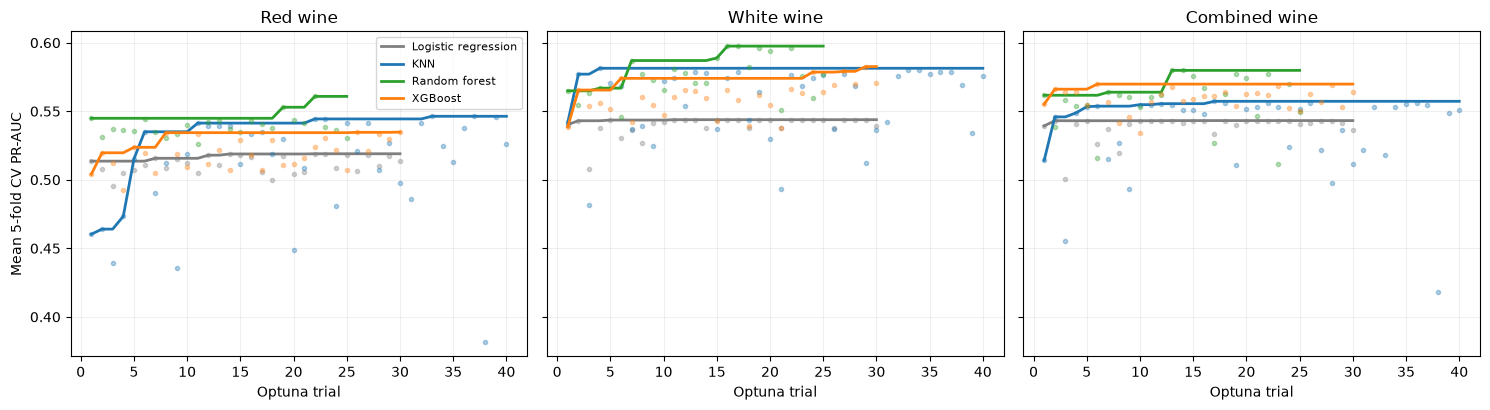

In [88]:
# optimization history: dots are single trials, the line is the best score found so far
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, name in zip(axes, DATASETS):
    for model_name in TUNED_MODELS:
        values = [trial.value for trial in studies[name][model_name].trials]
        trial_number = range(1, len(values) + 1)
        ax.plot(trial_number, values, ".", color=MODEL_COLOURS[model_name], alpha=0.35)
        ax.plot(trial_number, np.maximum.accumulate(values), color=MODEL_COLOURS[model_name], lw=2, label=model_name)
    ax.set_title(f"{name.capitalize()} wine")
    ax.set_xlabel("Optuna trial")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Mean 5-fold CV PR-AUC")
axes[0].legend(fontsize=8)
plt.tight_layout()
save_figure(fig, "optuna_history")
plt.show()

**Observations after tuning.**

- k-NN gains the most (about +0.10 on every dataset). The tuned models use many more neighbours (21 to 87) and distance weighting, which gives smoother probabilities.
- Logistic regression barely changes: its default penalty was already reasonable, and a linear model has little room to improve.
- Random forest gains little because its defaults were already good, but it remains the best model on all three datasets and is **selected for red, white and combined wine**. The tuned forests try only 1 or 2 measurements per split, which makes the trees more different from each other and the average more stable.
- Logistic regression and k-NN find their best settings within about 10 trials. The tree ensembles have more hyperparameters and keep improving slowly until late in the search (random forest up to trial 22 for red wine, XGBoost at trial 30 for white wine), so more trials might still help them a little.

## 7. Final evaluation on the test set

Each model is now scored **once** on the 20% test set that we put aside in section 1.2.

### 7.1 Choosing the decision threshold

In Tutorial 5 we saw that we can lower the decision threshold to predict "positive" more often, giving fewer false negatives at the cost of more false positives. With only 14 to 21% premium wines, the default threshold of 0.5 misses most premium wines.

For each model we choose the threshold that maximizes F1 (the balance of precision and recall). To avoid leakage, the threshold is chosen from **out-of-fold predictions on the training set** (`cross_val_predict`): every training wine is scored by a model that did not see it. The test set plays no part.

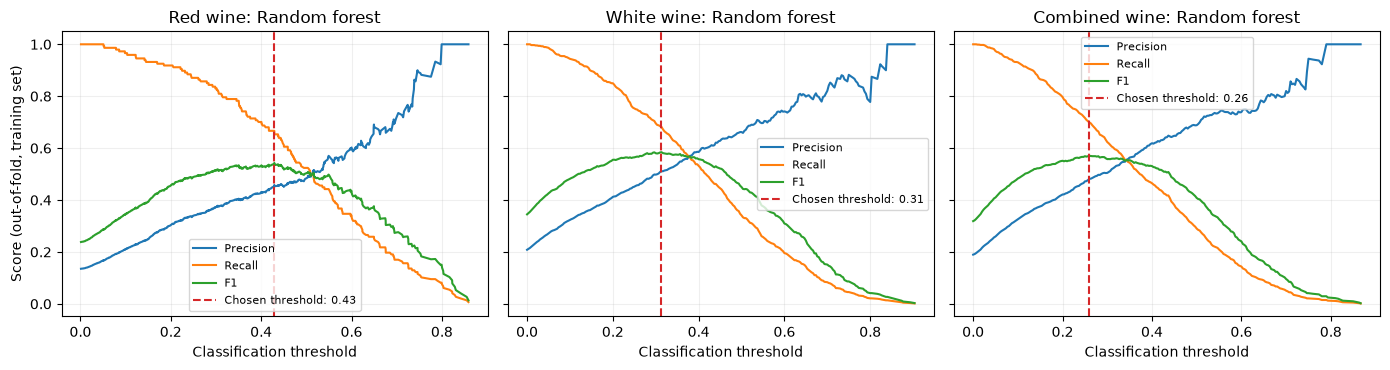

,red,white,combined
Dummy,0.500,0.500,0.500
Logistic regression,0.679,0.256,0.268
KNN,0.210,0.379,0.287
Random forest,0.429,0.313,0.260
XGBoost,0.195,0.147,0.295


In [89]:
final_models = {}
thresholds = {}
threshold_curves = {}

for name in DATASETS:
    X_train, y_train = splits[name]["X_train"], splits[name]["y_train"]
    final_models[name] = {"Dummy": make_dummy().fit(X_train, y_train), **tuned_models[name]}
    thresholds[name] = {"Dummy": 0.5}   # the dummy gives every wine the same score

    for model_name in TUNED_MODELS:
        features = features_for(name, model_name)
        # out-of-fold probabilities: each wine is predicted by a model trained on the other four folds
        oof_proba = cross_val_predict(clone(final_models[name][model_name]), X_train[features], y_train,
                                      cv=CV, method="predict_proba")[:, 1]
        precision, recall, cutoffs = precision_recall_curve(y_train, oof_proba)
        f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
        thresholds[name][model_name] = float(cutoffs[np.argmax(f1)])
        threshold_curves[(name, model_name)] = (cutoffs, precision[:-1], recall[:-1], f1)

# precision, recall and F1 against the threshold for the selected models
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, name in zip(axes, DATASETS):
    cutoffs, precision, recall, f1 = threshold_curves[(name, selected[name])]
    best = thresholds[name][selected[name]]
    ax.plot(cutoffs, precision, label="Precision")
    ax.plot(cutoffs, recall, label="Recall")
    ax.plot(cutoffs, f1, label="F1")
    ax.axvline(best, color="tab:red", linestyle="--", label=f"Chosen threshold: {best:.2f}")
    ax.set_title(f"{name.capitalize()} wine: {selected[name]}")
    ax.set_xlabel("Classification threshold")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Score (out-of-fold, training set)")
plt.tight_layout()
save_figure(fig, "threshold_selection")
plt.show()

pd.DataFrame(thresholds).round(3)

### 7.2 Test metrics with 95% intervals

The test set has only 37 premium red wines, so a single test score is uncertain. We estimate a **95% interval** for PR-AUC with 1,000 stratified **bootstrap** resamples of the test set (premium and standard wines are drawn separately, with replacement).

To check whether a model really beats the logistic regression baseline, we use a **paired bootstrap**: both models are scored on the same resampled wines, and we take the interval of the difference. If the interval stays above zero, the gain is statistically conclusive.

In [90]:
N_BOOTSTRAP = 1000
BASELINE = "Logistic regression"

def bootstrap_indices(y, n=N_BOOTSTRAP, seed=RANDOM_SEED):
    """Stratified resamples of the test set, reused for every model so differences can be paired."""
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    positives, negatives = np.where(y == 1)[0], np.where(y == 0)[0]
    return [np.concatenate([rng.choice(positives, len(positives)), rng.choice(negatives, len(negatives))])
            for _ in range(n)]

test_proba = {}
rows = []
for name in DATASETS:
    X_test, y_test = splits[name]["X_test"], splits[name]["y_test"].values
    resamples = bootstrap_indices(y_test)

    # predicted probabilities on the test set, and the PR-AUC of every bootstrap resample
    test_proba[name] = {m: final_models[name][m].predict_proba(X_test[features_for(name, m)])[:, 1] for m in MODELS}
    boot = {m: np.array([average_precision_score(y_test[i], test_proba[name][m][i]) for i in resamples]) for m in MODELS}

    for m in MODELS:
        metrics = get_classification_metrics(final_models[name][m], X_test[features_for(name, m)], y_test, thresholds[name][m])
        difference = boot[m] - boot[BASELINE]
        rows.append({"dataset": name, "model": m, "selected": m == selected[name], "threshold": thresholds[name][m],
                     **metrics,
                     "pr_auc_ci_low": np.percentile(boot[m], 2.5), "pr_auc_ci_high": np.percentile(boot[m], 97.5),
                     "no_skill_pr_auc": y_test.mean(),
                     "gain_vs_lr": metrics["pr_auc"] - average_precision_score(y_test, test_proba[name][BASELINE]),
                     "gain_ci_low": np.percentile(difference, 2.5), "gain_ci_high": np.percentile(difference, 97.5)})

test_table = pd.DataFrame(rows)
test_table.to_csv(os.path.join(TABLE_DIR, "test_results.csv"), index=False)
test_table.round(3)

,dataset,model,selected,threshold,pr_auc,roc_auc,accuracy,precision,recall,f1,pr_auc_ci_low,pr_auc_ci_high,no_skill_pr_auc,gain_vs_lr,gain_ci_low,gain_ci_high
0,red,Dummy,False,0.500,0.136,0.500,0.864,0.000,0.000,0.000,0.136,0.136,0.136,-0.422,-0.592,-0.306
1,red,Logistic regression,False,0.679,0.558,0.888,0.857,0.479,0.622,0.541,0.442,0.728,0.136,0.000,0.000,0.000
2,red,KNN,False,0.210,0.538,0.861,0.824,0.410,0.676,0.510,0.408,0.678,0.136,-0.020,-0.140,0.075
3,red,Random forest,True,0.429,0.567,0.883,0.860,0.489,0.622,0.548,0.443,0.722,0.136,0.009,-0.123,0.135
4,red,XGBoost,False,0.195,0.531,0.890,0.842,0.455,0.811,0.583,0.419,0.677,0.136,-0.027,-0.144,0.093
5,white,Dummy,False,0.500,0.208,0.500,0.792,0.000,0.000,0.000,0.208,0.208,0.208,-0.386,-0.455,-0.319
6,white,Logistic regression,False,0.256,0.594,0.830,0.773,0.471,0.745,0.577,0.527,0.663,0.208,0.000,0.000,0.000
7,white,KNN,False,0.379,0.606,0.849,0.817,0.558,0.582,0.570,0.542,0.676,0.208,0.012,-0.044,0.075
8,white,Random forest,True,0.313,0.632,0.854,0.807,0.528,0.685,0.596,0.570,0.702,0.208,0.038,-0.013,0.092
9,white,XGBoost,False,0.147,0.639,0.866,0.776,0.477,0.800,0.597,0.572,0.714,0.208,0.045,-0.009,0.105


### 7.3 ROC and precision-recall curves

As in Tutorial 5, we compute the ROC curve with `roc_curve` and its area with `auc`. Below it we plot the precision-recall curve of the same predictions. The thick line is the selected model, and the dotted line is no skill.

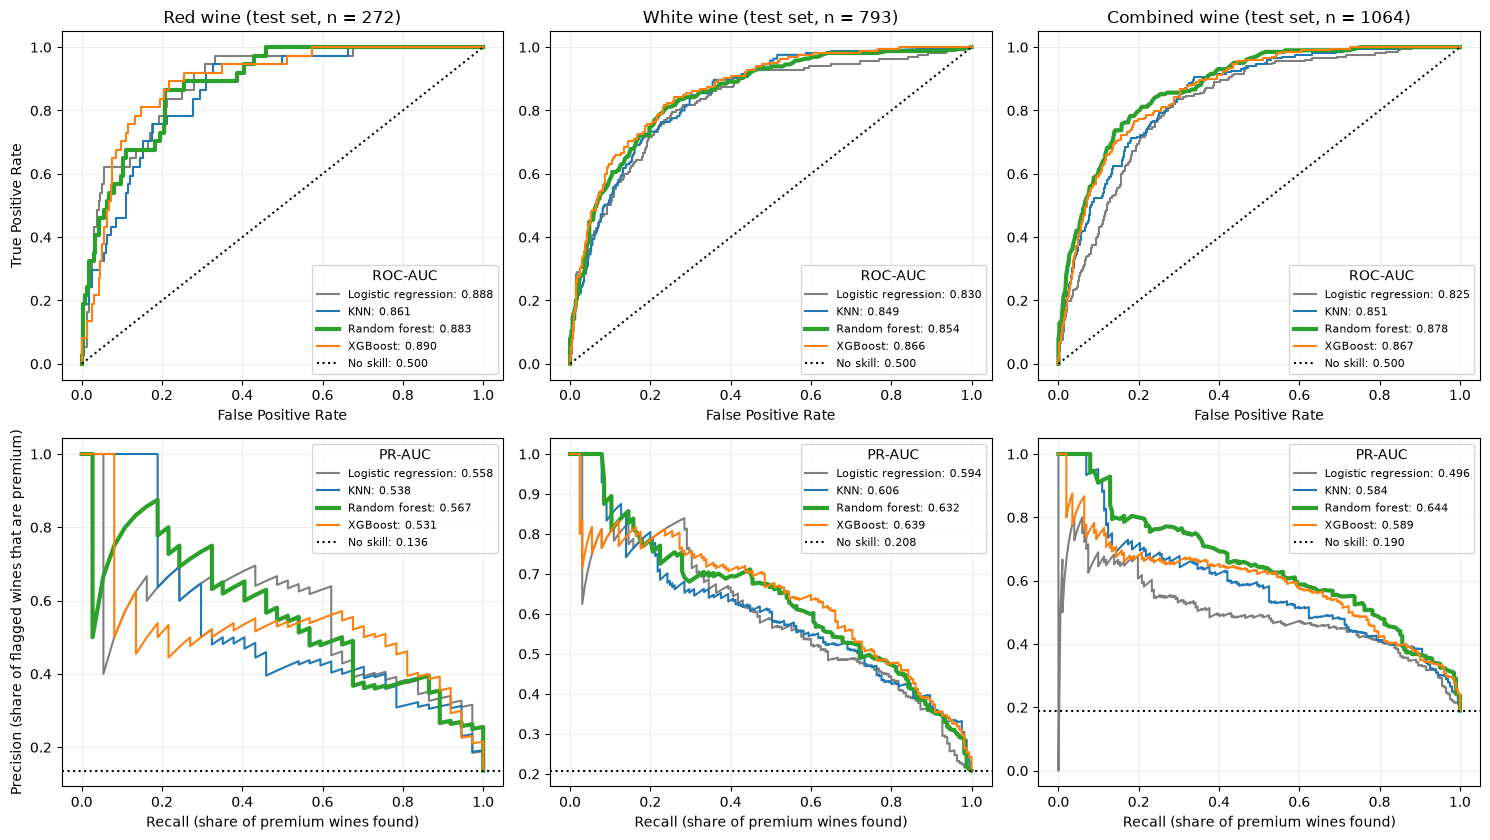

In [91]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for j, name in enumerate(DATASETS):
    y_test = splits[name]["y_test"].values
    for m in TUNED_MODELS:
        y_proba = test_proba[name][m]
        width = 3 if m == selected[name] else 1.5

        # ROC curve
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        roc_auc = auc(fpr, tpr)
        axes[0, j].plot(fpr, tpr, color=MODEL_COLOURS[m], lw=width, label=f"{m}: {roc_auc:.3f}")

        # precision-recall curve
        precision, recall, _ = precision_recall_curve(y_test, y_proba)
        axes[1, j].plot(recall, precision, color=MODEL_COLOURS[m], lw=width,
                        label=f"{m}: {average_precision_score(y_test, y_proba):.3f}")

    axes[0, j].plot([0, 1], [0, 1], ":", color="k", label="No skill: 0.500")
    axes[1, j].axhline(y_test.mean(), linestyle=":", color="k", label=f"No skill: {y_test.mean():.3f}")
    axes[0, j].set_title(f"{name.capitalize()} wine (test set, n = {len(y_test)})")
    axes[0, j].set_xlabel("False Positive Rate")
    axes[1, j].set_xlabel("Recall (share of premium wines found)")
    axes[0, j].legend(title="ROC-AUC", fontsize=8, loc="lower right")
    axes[1, j].legend(title="PR-AUC", fontsize=8, loc="upper right")
axes[0, 0].set_ylabel("True Positive Rate")
axes[1, 0].set_ylabel("Precision (share of flagged wines that are premium)")
for ax in axes.flat:
    ax.grid(alpha=0.2)
plt.tight_layout()
save_figure(fig, "roc_and_pr_curves")
plt.show()

### 7.4 Confusion matrices: baseline against the selected model

As in Tutorial 5, we use `ConfusionMatrixDisplay`. Rows are the true class and columns the predicted class, at each model's threshold from section 7.1. The bottom left cell (false negatives) is the premium wines we miss; the top right cell (false positives) is the false alarms that would be sent to the tasting panel.

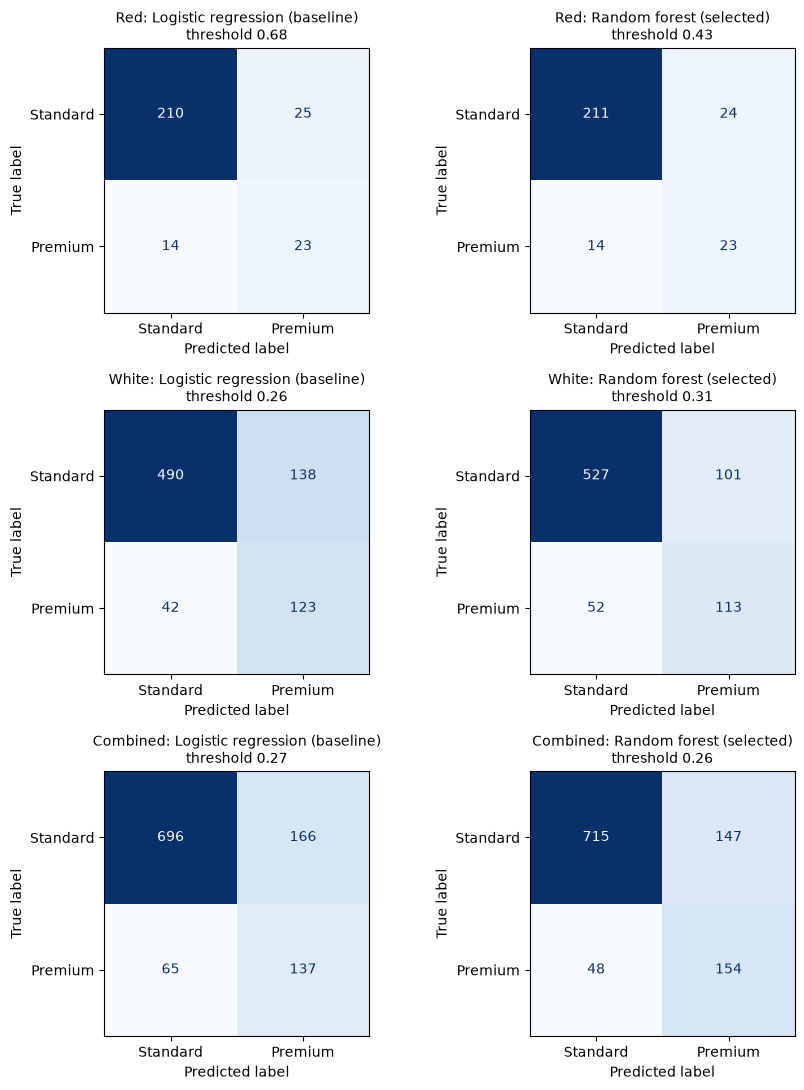

,dataset,model,threshold,TN,FP,FN,TP
0,red,Logistic regression,0.678755,210,25,14,23
1,red,Random forest,0.429172,211,24,14,23
2,white,Logistic regression,0.255996,490,138,42,123
3,white,Random forest,0.313333,527,101,52,113
4,combined,Logistic regression,0.267797,696,166,65,137
5,combined,Random forest,0.260000,715,147,48,154


In [92]:
fig, axes = plt.subplots(3, 2, figsize=(9, 11))
class_labels = ["Standard", "Premium"]
rows = []
for i, name in enumerate(DATASETS):
    y_test = splits[name]["y_test"].values
    for j, m in enumerate([BASELINE, selected[name]]):
        y_pred = (test_proba[name][m] >= thresholds[name][m]).astype(int)
        cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
        (tn, fp), (fn, tp) = cm
        rows.append({"dataset": name, "model": m, "threshold": thresholds[name][m], "TN": tn, "FP": fp, "FN": fn, "TP": tp})

        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
        disp.plot(cmap=plt.cm.Blues, ax=axes[i, j], colorbar=False)
        role = "baseline" if j == 0 else "selected"
        axes[i, j].set_title(f"{name.capitalize()}: {m} ({role})\nthreshold {thresholds[name][m]:.2f}", fontsize=10)
plt.tight_layout()
save_figure(fig, "confusion_matrices")
plt.show()

confusion_table = pd.DataFrame(rows)
confusion_table.to_csv(os.path.join(TABLE_DIR, "confusion_matrices.csv"), index=False)
confusion_table

**Observations on the test set.**

- Random forest reaches a test PR-AUC of 0.567 (red), 0.632 (white) and 0.644 (combined), three to four times the no-skill level. The 0.60 target is met for white and combined wine but not for red.
- The gain over logistic regression is statistically conclusive only for the combined dataset (+0.15). For red and white wine the bootstrap interval of the gain includes zero: with only 37 premium red wines in the test set, the test cannot separate the models.
- On the combined test set the forest finds 154 of 202 premium wines (76%) against 137 for logistic regression, and raises fewer false alarms (147 against 166).
- ROC-AUC values are all between 0.83 and 0.89 and hardly separate the models, while PR-AUC shows clearer differences. This supports our choice of PR-AUC as the main metric.

## 8. Interpretation

### 8.1 Which measurements drive the selected models?

We use **permutation importance**: shuffle one measurement at a time and measure how much the PR-AUC drops. A large drop means the model relies on that measurement. It works the same way for every model type. To keep the test set untouched, we compute it on the validation folds of the training set (the model is refitted on each fold) and average over the five folds.

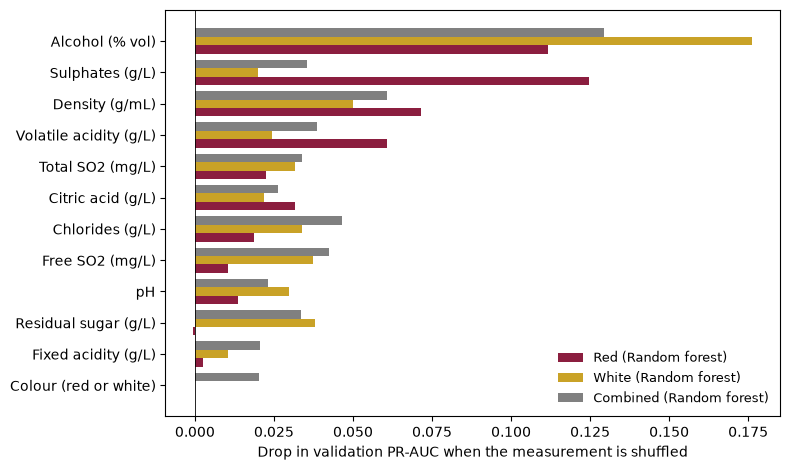

,red,white,combined
alcohol,0.112,0.176,0.129
chlorides,0.019,0.034,0.046
citric_acid,0.032,0.022,0.026
colour,0.000,0.000,0.020
density,0.072,0.050,0.061
fixed_acidity,0.003,0.010,0.021
free_so2,0.010,0.037,0.043
pH,0.014,0.030,0.023
residual_sugar,-0.000,0.038,0.033
sulphates,0.125,0.020,0.035


In [93]:
importance = {}
for name in DATASETS:
    X_train, y_train = splits[name]["X_train"], splits[name]["y_train"]
    features = features_for(name, selected[name])
    fold_importance = []
    for train_idx, val_idx in CV.split(X_train, y_train):
        model = clone(final_models[name][selected[name]])
        model.fit(X_train.iloc[train_idx][features], y_train.iloc[train_idx])
        result = permutation_importance(model, X_train.iloc[val_idx][features], y_train.iloc[val_idx],
                                        scoring="average_precision", n_repeats=5, random_state=RANDOM_SEED)
        fold_importance.append(result.importances_mean)
    importance[name] = pd.Series(np.mean(fold_importance, axis=0), index=features)

importance = pd.DataFrame(importance).fillna(0)
importance.to_csv(os.path.join(TABLE_DIR, "permutation_importance.csv"))

order = importance[["red", "white"]].mean(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.8))
position = np.arange(len(order))
for k, name in enumerate(DATASETS):
    ax.barh(position + (k - 1) * 0.27, importance.loc[order, name], height=0.27,
            color=WINE_COLOURS[name], label=f"{name.capitalize()} ({selected[name]})")
ax.set_yticks(position)
ax.set_yticklabels([FEATURE_LABELS.get(f, "Colour (red or white)") for f in order])
ax.axvline(0, color="k", lw=0.6)
ax.set_xlabel("Drop in validation PR-AUC when the measurement is shuffled")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
save_figure(fig, "permutation_importance")
plt.show()

importance.round(3)

Alcohol and density are among the three most important measurements for every dataset, which matches the correlations in section 2.4 (density falls as alcohol rises). For red wine, sulphates is the most important measurement and volatile acidity also matters; for white wine, residual sugar and free SO2 contribute. The colour indicator adds almost nothing to the combined model, because the measurements themselves already separate red from white.

### 8.2 Does a model for one wine type work on the other?

Each type's selected model is applied, unchanged and without retraining, to the other type's test set.

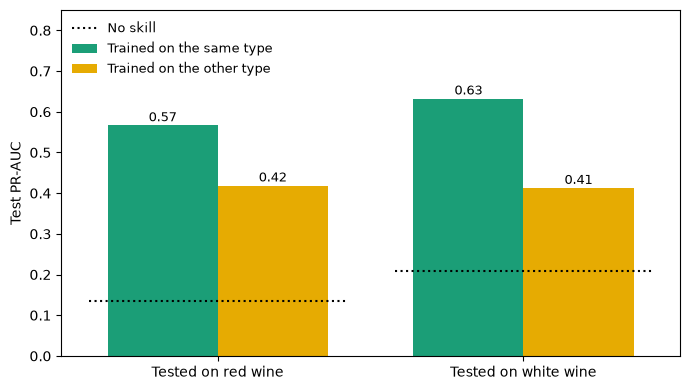

,tested_on,trained_on,model,test_pr_auc,no_skill_pr_auc
0,red,red,Random forest,0.567,0.136
1,red,white,Random forest,0.419,0.136
2,white,white,Random forest,0.632,0.208
3,white,red,Random forest,0.413,0.208


In [94]:
rows = []
for test_on, trained_on in [("red", "red"), ("red", "white"), ("white", "white"), ("white", "red")]:
    model = final_models[trained_on][selected[trained_on]]
    X_test, y_test = splits[test_on]["X_test"], splits[test_on]["y_test"]
    y_proba = model.predict_proba(X_test[features_for(trained_on, selected[trained_on])])[:, 1]
    rows.append({"tested_on": test_on, "trained_on": trained_on, "model": selected[trained_on],
                 "test_pr_auc": average_precision_score(y_test, y_proba), "no_skill_pr_auc": y_test.mean()})
transfer = pd.DataFrame(rows)
transfer.to_csv(os.path.join(TABLE_DIR, "transfer.csv"), index=False)

fig, ax = plt.subplots(figsize=(7, 4))
position = np.arange(2)
for k, (label, same_type) in enumerate([("Trained on the same type", True), ("Trained on the other type", False)]):
    values = transfer[(transfer["tested_on"] == transfer["trained_on"]) == same_type]["test_pr_auc"].values
    ax.bar(position + (k - 0.5) * 0.36, values, width=0.36, color=["#1B9E77", "#E6AB02"][k], label=label)
    for x, v in zip(position, values):
        ax.text(x + (k - 0.5) * 0.36, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
for x, name in zip(position, ["red", "white"]):
    no_skill = splits[name]["y_test"].mean()
    ax.plot([x - 0.42, x + 0.42], [no_skill, no_skill], ":", color="k", label="No skill" if x == 0 else None)
ax.set_xticks(position)
ax.set_xticklabels(["Tested on red wine", "Tested on white wine"])
ax.set_ylabel("Test PR-AUC")
ax.set_ylim(0, 0.85)
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout()
save_figure(fig, "transfer")
plt.show()

transfer.round(3)

A model trained on one wine type loses about a quarter to a third of its PR-AUC on the other type, although it stays well above no skill. The relationship between chemistry and quality differs between red and white wine (for example, sulphates matter for red but hardly for white), so each type needs its own model, or a combined model trained on both.

## 9. Summary

In [95]:
for name in DATASETS:
    r = test_table[(test_table["dataset"] == name) & test_table["selected"]].iloc[0]
    lr = test_table[(test_table["dataset"] == name) & (test_table["model"] == BASELINE)].iloc[0]
    tuning_row = tuning_table[(tuning_table["dataset"] == name) & (tuning_table["model"] == r["model"])].iloc[0]
    conclusive = "conclusive" if r["gain_ci_low"] > 0 else "not statistically conclusive"

    print(f"{name.upper()} WINE")
    print(f"  Selected model      : {r['model']} (CV PR-AUC {tuning_row['baseline_cv_pr_auc']:.3f} before tuning, "
          f"{tuning_row['tuned_cv_pr_auc']:.3f} after)")
    print(f"  Best settings       : {tuning_row['best_params']}")
    print(f"  Test PR-AUC         : {r['pr_auc']:.3f}  (95% interval {r['pr_auc_ci_low']:.2f} to {r['pr_auc_ci_high']:.2f}; "
          f"no skill {r['no_skill_pr_auc']:.3f})")
    print(f"  Target of 0.60      : {'met' if r['pr_auc'] >= 0.60 else 'not met'}")
    print(f"  Logistic regression : test PR-AUC {lr['pr_auc']:.3f}")
    print(f"  Gain over baseline  : {r['gain_vs_lr']:+.3f}  (95% interval {r['gain_ci_low']:+.2f} to "
          f"{r['gain_ci_high']:+.2f}; {conclusive})")
    print(f"  Test ROC-AUC        : {r['roc_auc']:.3f}")
    print(f"  At threshold {r['threshold']:.2f}   : precision {r['precision']:.0%}, recall {r['recall']:.0%}, F1 {r['f1']:.3f}")
    print(f"  Top 3 measurements  : {', '.join(importance[name].sort_values(ascending=False).index[:3])}\n")

print("Test PR-AUC of every model:")
print(test_table.pivot(index="model", columns="dataset", values="pr_auc").loc[MODELS, DATASETS].round(3))

RED WINE
  Selected model      : Random forest (CV PR-AUC 0.541 before tuning, 0.561 after)
  Best settings       : {'max_features': 1, 'min_samples_leaf': 4, 'max_depth': 20, 'class_weight': 'balanced_subsample'}
  Test PR-AUC         : 0.567  (95% interval 0.44 to 0.72; no skill 0.136)
  Target of 0.60      : not met
  Logistic regression : test PR-AUC 0.558
  Gain over baseline  : +0.009  (95% interval -0.12 to +0.13; not statistically conclusive)
  Test ROC-AUC        : 0.883
  At threshold 0.43   : precision 49%, recall 62%, F1 0.548
  Top 3 measurements  : sulphates, alcohol, density

WHITE WINE
  Selected model      : Random forest (CV PR-AUC 0.596 before tuning, 0.598 after)
  Best settings       : {'max_features': 2, 'min_samples_leaf': 1, 'max_depth': None, 'class_weight': None}
  Test PR-AUC         : 0.632  (95% interval 0.57 to 0.70; no skill 0.208)
  Target of 0.60      : met
  Logistic regression : test PR-AUC 0.594
  Gain over baseline  : +0.038  (95% interval -0.01 to 

**Conclusions.**

- Eleven routine lab measurements can rank wines by their chance of being premium far better than chance. A tuned random forest was the best model on every dataset in cross-validation.
- The 0.60 PR-AUC target is met for white and combined wine. For red wine it is not met, and the small number of premium red wines (184 in total, 37 in the test set) makes the red results the least certain.
- The forest clearly beats logistic regression on the combined dataset, where the relationship between chemistry and quality differs between the two wine types and a linear model cannot capture both. Within a single wine type, the gain over the linear baseline is not statistically conclusive.
- Alcohol is the dominant measurement, with density, and sulphates for red wine.

**Limitations.** The quality score is a subjective median of a few tasters, so some label noise is unavoidable. All wines come from one Portuguese region (Vinho Verde) and are 2004 to 2007 vintages, so the models may not transfer to other regions. The dataset contains no grape variety, price or producer information.

**Future work.** More premium red wines would make the red model more reliable. Repeated cross-validation with several seeds would narrow the uncertainty of the model comparison. Calibrating the predicted probabilities would let the threshold be set from the tasting panel's capacity (for example, "send the top 20% of wines").

In [96]:
# package versions used for this run, for reproducibility
import sys, sklearn, xgboost, matplotlib
print("Python      ", sys.version.split()[0])
for package in [np, pd, sklearn, xgboost, optuna, matplotlib, sns]:
    print(f"{package.__name__:12s} {package.__version__}")

Python       3.13.17
numpy        2.5.5
pandas       3.1.1
sklearn      1.9.1
xgboost      3.4.1
optuna       5.1.0
matplotlib   3.11.2
seaborn      0.13.2
